# Лабораторная работа № 6. Линейная регрессия
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** изучение принципов построения информационных систем с использованием линейных методов машинного обучения.

**Задачи:** освоить работу с линейной регрессией в задачах машинного обучения и Python; изучить способы применения регрессии и основные параметры регрессионных моделей.

**Данные:** Howpop для учебного примера; прежний RCAEval RE2-OB для индивидуальной регрессии и пунктов методички про дерево.

Работа выполнена по лабораторной № 6 методички *Practicum_AI_Methods.pdf*, с. 70–83.

## 1. Локальный запуск
Используем прежнее окружение Conda `rcaeval-ai` с Python 3.11 и scikit-learn 1.7. В VS Code выбираем его ядро и нажимаем **Run All**. Ноутбук работает из корня проекта и из `notebooks/`.

RCAEval читается из сохранённых файлов первой работы. Таблицы и графики сохраняются в папке этой лабораторной внутри `reports/`.

Подключаем библиотеки.

In [1]:
from pathlib import Path
from importlib.metadata import version
from itertools import combinations
from urllib.request import urlopen
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error

from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from matplotlib.patches import Patch

Задаём пути к данным и результатам.

In [2]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab06'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 17
sns.set_theme(style='whitegrid')

Выводим и сохраняем версии библиотек.

In [3]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn', 'scipy']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
numpy             2.2.6
pandas            2.3.3
matplotlib       3.10.9
seaborn          0.13.2
scikit-learn      1.7.2
scipy            1.17.1
Name: Версия, dtype: object

163

Определяем функцию сохранения и показа графиков.

In [4]:
def save_show(fig, name):
    fig.savefig(FIGURES / name, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

**Линейная регрессия** оценивает число как взвешенную сумму признаков плюс свободный член. В этой работе предсказываем показатель популярности статьи и числовую задержку сервиса. Это отличается от логистической регрессии, которая определяет класс.

**MSE** — средняя квадратичная ошибка, чем меньше, тем лучше. **MAE** — средняя ошибка по модулю, в той же шкале, что и ответ. **R²** сравнивает модель с постоянным средним значением на проверочных данных: 1 означает точное совпадение, 0 — уровень такого среднего, отрицательное значение — хуже него. Также отдельно обучаем простой baseline по среднему обучающих ответов.

**Ridge** — линейная регрессия с ограничением величины весов. Чем больше `alpha`, тем сильнее ограничение. Масштаб и словари признаков всегда обучаются только на обучающей части.

**Замечание к методичке:** в индивидуальном задании на с. 82 повторены пункты про дерево из работы № 4. Поэтому ниже выполнена регрессия по теме и цели работы, а в подразделе 3.7 — все шесть опубликованных пунктов про дерево. Учебный пример и контрольные вопросы также сохранены.

## 2. Учебная задача: популярность статей Howpop
### 2.1. Загрузка и первичное исследование
Воспроизводим пример с Хабром: читаем CSV, изучаем даты, корреляции и годы, превращаем заголовки и категории в числовые признаки, объединяем разреженные матрицы и сравниваем Ridge при alpha = 0,1 и 1.

Цель модели — `favs_lognorm`, уже преобразованный показатель добавлений статьи в избранное. Предсказываем его в исходной шкале этого столбца, а не число добавлений. Полные тексты в многогигабайтном JSON не нужны: в коде примера используются заголовок `title` и категории `author`, `flow`, `domain`, которые есть в CSV.

Скачиваем два учебных CSV только при отсутствии локальных копий.

In [5]:
HOWPOP = ROOT / 'data/raw/howpop'
HOWPOP.mkdir(parents=True, exist_ok=True)
course_revision = '1a80eacf240821fd67525b0e0a44a20da9313f1f'
course_base = f'https://raw.githubusercontent.com/zikrach/mlcourse_open/{course_revision}/data/'
for name in ['howpop_train.csv', 'howpop_test.csv']:
    path = HOWPOP / name
    if not path.exists():
        path.write_bytes(urlopen(course_base + name, timeout=90).read())

Читаем обучающие и тестовые статьи.

In [6]:
articles = pd.read_csv(HOWPOP / 'howpop_train.csv', parse_dates=['published'])
articles_test = pd.read_csv(HOWPOP / 'howpop_test.csv', parse_dates=['published'])

Показываем по одной статье вертикально, размеры и типы столбцов.

In [7]:
display(articles.head(1).T)
display(articles_test.head(1).T)
print('Обучающая таблица:', articles.shape, '| Таблица без ответов:', articles_test.shape)
articles.info()

,0
url,https://habrahabr.ru/post/18284/
domain,habrahabr.ru
post_id,18284
published,2008-01-01 18:19:00
author,@Tapac
flow,develop
polling,False
content_len,4305
title,Новогодний подарок блоггерам — WordPress 2.3.2
comments,0


,0
url,https://habrahabr.ru/post/314080/
domain,habrahabr.ru
post_id,314080
published,2016-11-01 01:05:00
author,@fsou11
flow,develop
polling,True
content_len,20132
title,Опыт использования MassTransit 3.0


Обучающая таблица: (134137, 17) | Таблица без ответов: (3990, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134137 entries, 0 to 134136
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   url               134137 non-null  object        
 1   domain            134137 non-null  object        
 2   post_id           134137 non-null  int64         
 3   published         134137 non-null  datetime64[ns]
 4   author            97657 non-null   object        
 5   flow              97048 non-null   object        
 6   polling           134137 non-null  bool          
 7   content_len       134137 non-null  int64         
 8   title             134137 non-null  object        
 9   comments          134137 non-null  int64         
 10  favs              134137 non-null  int64         
 11  views             134137 non-null  int64         
 12  votes_plus        133566 non-null  float64       

Проверяем порядок дат публикации и показываем его на графике.

Даты упорядочены: True


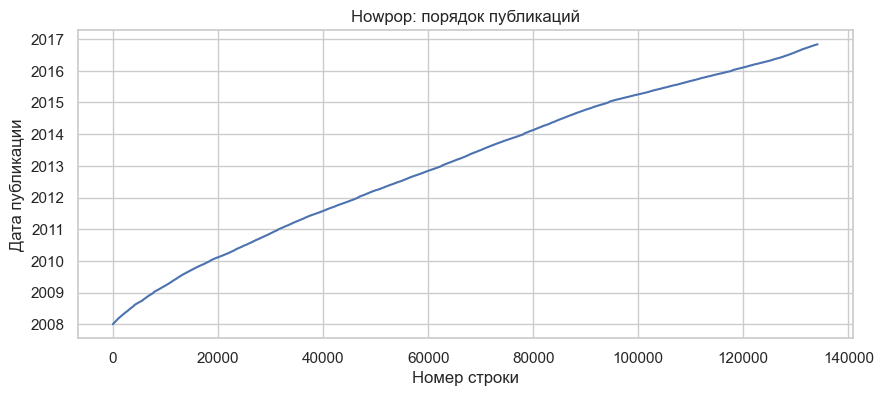

In [8]:
print('Даты упорядочены:', articles.published.is_monotonic_increasing)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(len(articles)), articles.published)
ax.set(title='Howpop: порядок публикаций', xlabel='Номер строки', ylabel='Дата публикации')
save_show(fig, '01_howpop_dates.png')

Рост линии означает, что следующие строки относятся к более поздним публикациям. Это важно для разделения: обучаемся на более ранних статьях и проверяемся на более поздних, а не перемешиваем их случайно.

Считаем корреляции числовых столбцов и находим пары с модулем выше 0,9.

Series([], Name: Корреляция, dtype: float64)

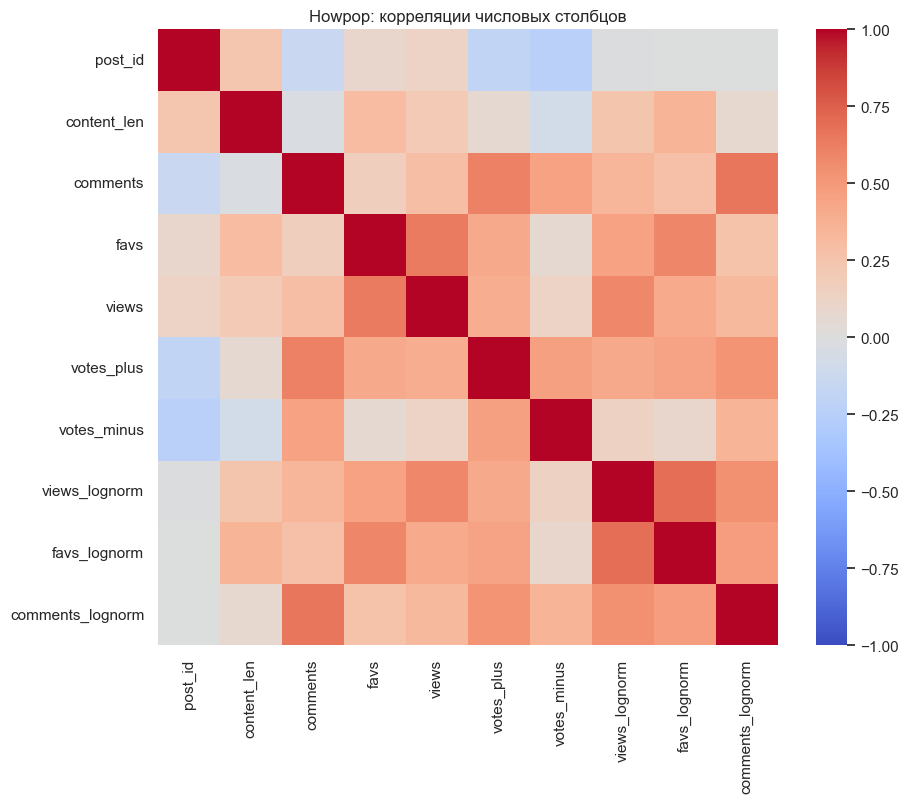

In [9]:
numeric_corr = articles.select_dtypes(include='number').corr()
upper = numeric_corr.where(np.triu(np.ones(numeric_corr.shape), k=1).astype(bool))
strong_pairs = upper.stack().loc[lambda values: values.abs() > 0.9]
display(strong_pairs.rename('Корреляция'))
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(numeric_corr, cmap='coolwarm', vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title('Howpop: корреляции числовых столбцов')
save_show(fig, '02_howpop_correlations.png')

Яркие клетки около −1 и 1 показывают сильную линейную связь. Повторные пары и диагональ удалены из таблицы. Отсутствие коэффициентов выше 0,9 **не доказывает независимость** признаков. Числовые показатели отклика здесь рассматриваются только для описания данных, в модель далее не входят.

Считаем статьи по годам и строим график.

published
2008     7743
2009    10783
2010    13091
2011    15063
2012    15972
2013    15537
2014    16180
2015    23452
2016    16316
Name: Публикаций, dtype: int64

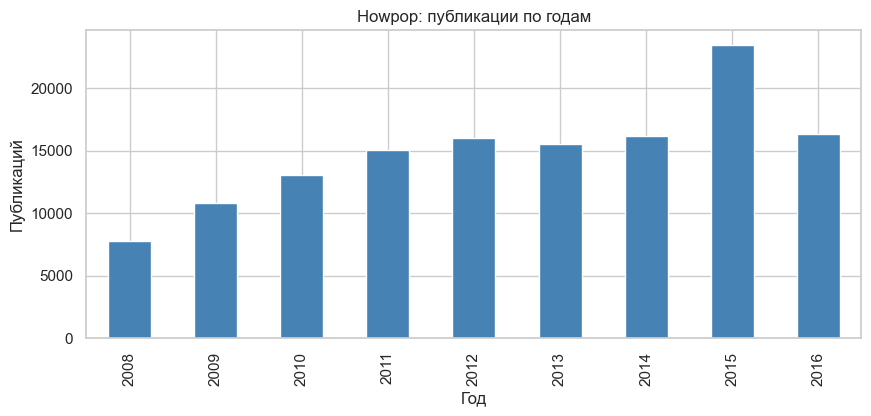

In [10]:
year_counts = articles.published.dt.year.value_counts().sort_index()
display(year_counts.rename('Публикаций'))
fig, ax = plt.subplots(figsize=(10, 4))
year_counts.plot.bar(ax=ax, color='steelblue')
ax.set(title='Howpop: публикации по годам', xlabel='Год', ylabel='Публикаций')
save_show(fig, '03_howpop_years.png')

Высота столбца — число статей за год в этой таблице. Это не показатель популярности отдельной статьи. Последний год может содержать неполный период, поэтому сравнение годовых количеств требует учёта дат.

### 2.2. Подготовка текстовых и категориальных признаков
Используем только заголовок, автора, раздел и домен — как в листингах методички. Число избранных, просмотры, комментарии и их преобразования в признаки не входят: они относятся к результатам публикации и могут раскрывать ответ.

Отделяем последние 30% известных статей для проверки. `TF-IDF` превращает текст в числа: учитывает присутствие слов и уменьшает влияние слов, встречающихся почти повсюду. Словарь строим по ранним статьям, для остальных вызываем только `transform`.

Упорядочиваем статьи, выбираем признаки и разделяем по времени.

In [11]:
articles = articles.sort_values('published').reset_index(drop=True)
article_features = ['title', 'author', 'flow', 'domain']
article_cut = int(len(articles) * 0.7)
A_train = articles.iloc[:article_cut][article_features].fillna('-')
A_valid = articles.iloc[article_cut:][article_features].fillna('-')
A_test = articles_test[article_features].fillna('-')
yh_train = articles.favs_lognorm.iloc[:article_cut]
yh_valid = articles.favs_lognorm.iloc[article_cut:]
print('Обучение:', len(A_train), '| Проверка:', len(A_valid))

Обучение: 93895 | Проверка: 40242


Создаём словарную TF-IDF-матрицу заголовков.

In [12]:
word_vectorizer = TfidfVectorizer(min_df=3, max_df=0.3, ngram_range=(1, 3))
word_train = word_vectorizer.fit_transform(A_train.title)
word_valid = word_vectorizer.transform(A_valid.title)
word_test = word_vectorizer.transform(A_test.title)
print('Матрицы:', word_train.shape, word_valid.shape, word_test.shape)

Матрицы: (93895, 50624) (40242, 50624) (3990, 50624)


Показываем часть обученного словаря.

In [13]:
display(pd.Series(word_vectorizer.vocabulary_).head(10).rename('Номер признака'))
print('Слов и сочетаний в словаре:', len(word_vectorizer.vocabulary_))

новогодний            31497
подарок               36257
блоггерам             14241
wordpress             12172
новогодний подарок    31499
сумасшедшие           45476
яйца                  50489
или                   22661
сервис                42745
для                   18811
Name: Номер признака, dtype: int64

Слов и сочетаний в словаре: 50624


Создаём TF-IDF-матрицу по отдельным символам, как в примере.

In [14]:
char_vectorizer = TfidfVectorizer(analyzer='char')
char_train = char_vectorizer.fit_transform(A_train.title)
char_valid = char_vectorizer.transform(A_valid.title)
char_test = char_vectorizer.transform(A_test.title)
print('Символьные матрицы:', char_train.shape, char_valid.shape, char_test.shape)

Символьные матрицы: (93895, 218) (40242, 218) (3990, 218)


Словарная часть учитывает слова и последовательности до трёх слов. Символьная часть здесь учитывает отдельные символы — это настройки показанного примера, а не модель полного содержания статьи. Оба словаря одинаковы для обучения, проверки и неизвестных статей.

Преобразуем автора, раздел и домен через DictVectorizer.

In [15]:
category_features = ['author', 'flow', 'domain']
dict_vectorizer = DictVectorizer()
category_train = dict_vectorizer.fit_transform(A_train[category_features].to_dict('records'))
category_valid = dict_vectorizer.transform(A_valid[category_features].to_dict('records'))
category_test = dict_vectorizer.transform(A_test[category_features].to_dict('records'))
print('Категориальные матрицы:', category_train.shape, category_valid.shape, category_test.shape)

Категориальные матрицы: (93895, 17869) (40242, 17869) (3990, 17869)


Объединяем три разреженных блока.

In [16]:
Ah_train = hstack([word_train, category_train, char_train], format='csr')
Ah_valid = hstack([word_valid, category_valid, char_valid], format='csr')
Ah_test = hstack([word_test, category_test, char_test], format='csr')
print('Объединённые матрицы:', Ah_train.shape, Ah_valid.shape, Ah_test.shape)

Объединённые матрицы: (93895, 68711) (40242, 68711) (3990, 68711)


Объединение допустимо, потому что строки всех блоков относятся к тем же статьям и идут в одном порядке. Число строк внутри каждой подвыборки совпадает. Блоки имеют разные признаки, поэтому складываем их рядом, по столбцам. Словари на проверке не переобучаются.

### 2.3. Ridge при двух alpha и сравнение с baseline

Обучаем две Ridge-модели и считаем ошибки.

In [17]:
howpop_rows = []
howpop_models = {}
for alpha in [0.1, 1.0]:
    model = Ridge(alpha=alpha, solver='lsqr').fit(Ah_train, yh_train)
    howpop_models[alpha] = model
    howpop_rows.append({'alpha': alpha,
                       'train_MSE': mean_squared_error(yh_train, model.predict(Ah_train)),
                       'validation_MSE': mean_squared_error(yh_valid, model.predict(Ah_valid))})
howpop_comparison = pd.DataFrame(howpop_rows)
display(howpop_comparison)

,alpha,train_MSE,validation_MSE
0,0.1,0.185607,0.900427
1,1.0,0.287016,0.700750


Строим график обучающей и проверочной ошибки.

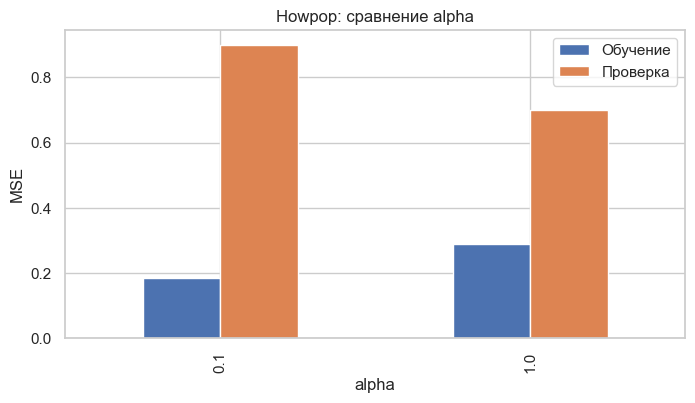

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
howpop_comparison.set_index('alpha')[['train_MSE', 'validation_MSE']].plot.bar(ax=ax)
ax.set(title='Howpop: сравнение alpha', xlabel='alpha', ylabel='MSE')
ax.legend(['Обучение', 'Проверка'])
save_show(fig, '04_howpop_alpha.png')

Низкий столбец означает меньшую ошибку. Ошибка на обучении обычно меньше проверочной: эти статьи модель уже видела. Усиление ограничения весов может повысить обучающую ошибку и одновременно уменьшить проверочную. Выбираем по проверочной ошибке, а не по способности запомнить обучение.

Сравниваем выбранную модель со средним ответом и сохраняем прогноз неизвестных статей.

In [19]:
howpop_best_alpha = float(howpop_comparison.loc[howpop_comparison.validation_MSE.idxmin(), 'alpha'])
howpop_model = howpop_models[howpop_best_alpha]
howpop_prediction = howpop_model.predict(Ah_valid)
howpop_baseline_mse = mean_squared_error(yh_valid, np.full(len(yh_valid), yh_train.mean()))
print('Выбрано alpha:', howpop_best_alpha)
print('MSE модели:', mean_squared_error(yh_valid, howpop_prediction))
print('MSE постоянного среднего обучающих ответов:', howpop_baseline_mse)
pd.DataFrame({'url': articles_test.url, 'favs_lognorm': howpop_model.predict(Ah_test)}).to_csv(
    REPORT / 'howpop_predictions.csv', index=False)

Выбрано alpha: 1.0
MSE модели: 0.7007497751489428
MSE постоянного среднего обучающих ответов: 1.0020584058477109


Прогноз для неизвестных статей сохранён вместе с URL, чтобы не потерять порядок. Модель обучена на первых 70% известных статей. Последние 30% использовались для выбора между двумя alpha, поэтому их ошибку считаем проверочной оценкой подбора. Настоящих ответов тестовых статей нет; качество на них не вычисляем.

## 3. Индивидуальная работа на RCAEval
### 3.1. Данные и числовой ответ
Используем прежний CPU-сценарий Online Boutique. Одна строка — измерение в один момент. Для основной задачи регрессии оцениваем **медианную задержку checkoutservice** по CPU, памяти и показателю socket в тот же момент.

Задержка не входит в признаки. Это оценка текущего показателя по другим метрикам, а не прогноз задержки в будущем. Точные единицы задержки в локальном файле не указаны, поэтому все ошибки относятся к исходной шкале столбца.

**Согласование датасета с преподавателем:** ____________________  
**Дата:** ____________________

Читаем имя прежнего сценария.

In [20]:
selection = json.loads((ROOT / 'reports/lab01/selected_case.json').read_text(encoding='utf-8'))
case = selection['case']
case_dir = ROOT / 'data/raw/rcaeval' / case

Загружаем сохранённые метрики и время внесения сбоя.

In [21]:
metrics_path = case_dir / 'metrics.parquet'
inject_path = case_dir / 'inject_time.txt'
df = pd.read_parquet(metrics_path)
inject_time = int(inject_path.read_text(encoding='utf-8').strip())

Печатаем первые строки и сведения о данных.

In [22]:
display(df.head())
print('Сценарий:', case, '| Сервис:', selection['root_cause_service'], '| Сбой:', selection['fault'])
print('Строк:', len(df), '| Метрик:', df.shape[1] - 1)
print('Момент внесения:', pd.to_datetime(inject_time, unit='s', utc=True))

,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,paymentservice_cpu,productcatalogservice_cpu,recommendationservice_cpu,...,adservice_latency-90,cartservice_latency-90,checkoutservice_latency-90,currencyservice_latency-90,emailservice_latency-90,frontend_latency-90,paymentservice_latency-90,productcatalogservice_latency-90,recommendationservice_latency-90,shippingservice_latency-90
0,1705353846,0.685023,2.216467,0.215886,19.035876,0.279166,6.724489,0.52931,2.636831,2.474853,...,0.004604,0.004993,0.850000,0.110638,0.0046,0.819737,0.008955,0.004418,0.009670,0.004576
1,1705353847,0.685023,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.636858,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008955,0.004423,0.009672,0.004576
2,1705353848,0.582707,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.584059,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008636,0.004423,0.009672,0.004576
3,1705353849,0.625903,2.216467,0.380058,19.106596,0.279166,6.724489,0.52931,3.250317,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576
4,1705353850,0.613414,2.216467,0.380058,19.106596,0.279166,5.572668,0.52931,3.250317,2.474853,...,0.004594,0.006304,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576


Сценарий: re2ob_checkoutservice_cpu_1 | Сервис: checkoutservice | Сбой: cpu
Строк: 1441 | Метрик: 72
Момент внесения: 2024-01-15 21:36:06+00:00


Выбираем три признака и целевую задержку.

In [23]:
regression_features = ['checkoutservice_cpu', 'checkoutservice_mem', 'checkoutservice_socket']
target_column = 'checkoutservice_latency-50'
Xr = df[regression_features].copy()
yr = df[target_column].copy()
display(pd.DataFrame({'Тип': df[regression_features + [target_column]].dtypes,
                      'Пропуски': df[regression_features + [target_column]].isna().sum()}))

,Тип,Пропуски
checkoutservice_cpu,float64,0
checkoutservice_mem,float64,0
checkoutservice_socket,float64,0
checkoutservice_latency-50,float64,0


Признаки и ответ числовые, пропусков в них нет. Ничего не заполняем и не удаляем. Время не входит в X; оно используется только для разделения данных и графика.

Отделяем минутные участки для итоговой проверки.

In [24]:
groups = ((df.time - df.time.min()) // 60).astype(int)
period = (df.time >= inject_time).astype(int)
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
reg_dev_idx, reg_test_idx = next(outer_cv.split(Xr, period, groups))
Xr_dev, Xr_test = Xr.iloc[reg_dev_idx], Xr.iloc[reg_test_idx]
yr_dev, yr_test = yr.iloc[reg_dev_idx], yr.iloc[reg_test_idx]
reg_groups_dev = groups.iloc[reg_dev_idx]
reg_cv = GroupKFold(n_splits=5)
print('Подбор:', len(Xr_dev), '| Итоговая проверка:', len(Xr_test))

Подбор: 1141 | Итоговая проверка: 300


Минутные участки сохраняются целиком. Внешнее разделение учитывает периоды, чтобы в подвыборках были измерения до и после, но метка периода не передаётся регрессионной модели. Для подбора alpha используем GroupKFold на оставшихся участках. Все данные всё ещё относятся к одному эксперименту.

### 3.2. Baseline и обычная линейная регрессия

Обучаем постоянный baseline и линейную регрессию.

In [25]:
mean_model = DummyRegressor(strategy='mean').fit(Xr_dev, yr_dev)
linear_model = make_pipeline(StandardScaler(), LinearRegression()).fit(Xr_dev, yr_dev)

Проверяем обычную линейную регрессию по пяти частям.

In [26]:
linear_cv_mse = -cross_val_score(make_pipeline(StandardScaler(), LinearRegression()),
    Xr_dev, yr_dev, groups=reg_groups_dev, cv=reg_cv, scoring='neg_mean_squared_error').mean()
print('Средняя MSE линейной регрессии по CV:', linear_cv_mse)

Средняя MSE линейной регрессии по CV: 0.003350484785316411


### 3.3. Подбор регуляризации Ridge

Сравниваем alpha по ошибке CV.

In [27]:
alpha_values = np.logspace(-3, 3, 13)
alpha_rows = []
for alpha in alpha_values:
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    scores = -cross_val_score(model, Xr_dev, yr_dev, groups=reg_groups_dev,
                              cv=reg_cv, scoring='neg_mean_squared_error')
    alpha_rows.append({'alpha': alpha, 'MSE': scores.mean(), 'std': scores.std()})
alpha_table = pd.DataFrame(alpha_rows)
display(alpha_table)

,alpha,MSE,std
0,0.001000,0.003350,0.000444
1,0.003162,0.003350,0.000444
2,0.010000,0.003350,0.000444
3,0.031623,0.003350,0.000444
4,0.100000,0.003349,0.000443
5,0.316228,0.003348,0.000442
6,1.000000,0.003345,0.000441
7,3.162278,0.003347,0.000455
8,10.000000,0.003356,0.000491
9,31.622777,0.003362,0.000526


Строим график ошибки Ridge при разных alpha.

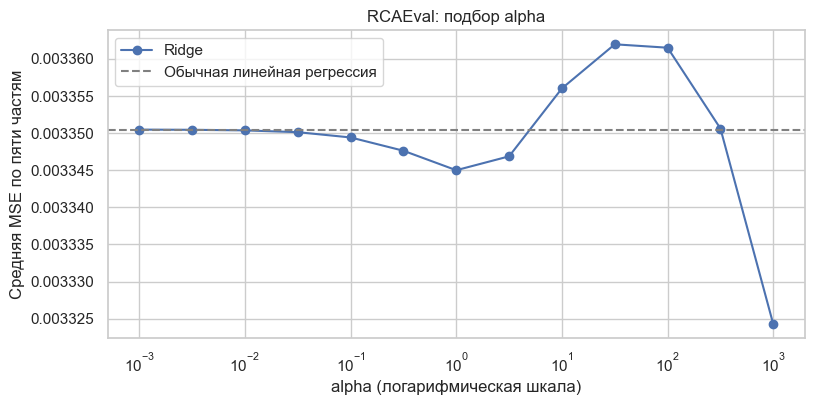

In [28]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogx(alpha_table.alpha, alpha_table.MSE, marker='o', label='Ridge')
ax.axhline(linear_cv_mse, color='gray', linestyle='--', label='Обычная линейная регрессия')
ax.set(title='RCAEval: подбор alpha', xlabel='alpha (логарифмическая шкала)', ylabel='Средняя MSE по пяти частям')
ax.legend()
save_show(fig, '05_rca_alpha.png')

Чем ниже точка, тем меньше ошибка оценки задержки. Пунктир показывает обычную линейную регрессию по тем же частям. Большое alpha сильнее ограничивает веса и может сделать ответы слишком похожими. Выбираем alpha с минимальной MSE; при равенстве берём первое, меньшее значение из сетки.

В этой сетке выбрано alpha = 1000 — наибольшее из 13 проверенных значений. Это лучший вариант в указанной сетке, а не доказанный минимум среди всех возможных alpha. Разница CV-ошибок небольшая; итоговый результат сравниваем со средним ответом отдельно.

Обучаем Ridge с выбранным alpha.

In [29]:
best_alpha = float(alpha_table.loc[alpha_table.MSE.idxmin(), 'alpha'])
ridge_model = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha)).fit(Xr_dev, yr_dev)
print('Выбрано alpha:', best_alpha)

Выбрано alpha: 1000.0


### 3.4. Итоговая проверка числовых ответов

Сравниваем baseline, линейную регрессию и выбранную Ridge на отложенных минутах.

In [30]:
metric_rows = []
for name, model in [('Среднее обучения', mean_model), ('Линейная регрессия', linear_model), ('Ridge', ridge_model)]:
    predicted = model.predict(Xr_test)
    metric_rows.append({'Модель': name, 'MSE': mean_squared_error(yr_test, predicted),
                        'MAE': mean_absolute_error(yr_test, predicted), 'R2': r2_score(yr_test, predicted)})
regression_metrics = pd.DataFrame(metric_rows)
display(regression_metrics)
reg_prediction = ridge_model.predict(Xr_test)

,Модель,MSE,MAE,R2
0,Среднее обучения,0.005470,0.055891,-0.004957
1,Линейная регрессия,0.005661,0.055049,-0.040050
2,Ridge,0.005562,0.054291,-0.021893


Все три строки рассчитаны на одинаковых отложенных измерениях. Здесь видно, полезнее ли метрики, чем просто среднее значение обучения. Итоговые ошибки не используем для повторного выбора alpha. Даже если Ridge оказалась хуже простого baseline, сохраняем и объясняем полученный результат.

Показываем несколько настоящих и предсказанных задержек.

In [31]:
reg_answers = pd.DataFrame({'row': Xr_test.index, 'time': df.loc[Xr_test.index, 'time'].to_numpy(),
                            'actual': yr_test.to_numpy(), 'prediction': reg_prediction})
reg_answers['error'] = reg_answers.prediction - reg_answers.actual
display(reg_answers.head(10))

,row,time,actual,prediction,error
0,0,1705353846,0.243182,0.298136,0.054954
1,1,1705353847,0.299999,0.298194,-0.001805
2,2,1705353848,0.299999,0.298194,-0.001805
3,3,1705353849,0.299999,0.298194,-0.001805
4,4,1705353850,0.299999,0.298194,-0.001805
5,5,1705353851,0.299999,0.298194,-0.001805
6,6,1705353852,0.312500,0.298185,-0.014315
7,7,1705353853,0.312500,0.298188,-0.014312
8,8,1705353854,0.312500,0.298190,-0.014310
9,9,1705353855,0.312500,0.298193,-0.014307


Сравниваем настоящие и предсказанные значения на диаграмме.

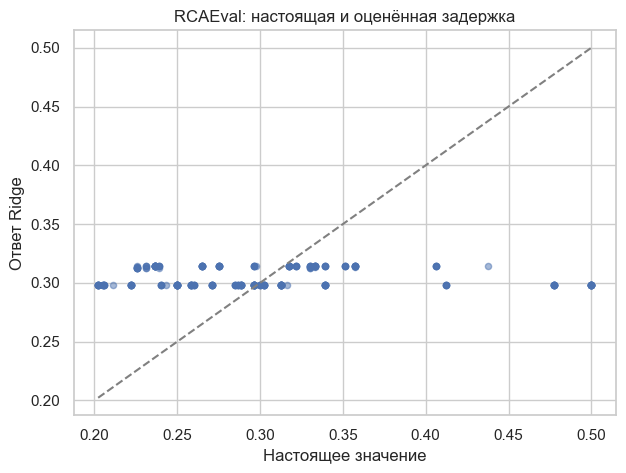

In [32]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(yr_test, reg_prediction, s=20, alpha=0.5)
low = min(yr_test.min(), reg_prediction.min())
high = max(yr_test.max(), reg_prediction.max())
ax.plot([low, high], [low, high], '--', color='gray')
ax.set(title='RCAEval: настоящая и оценённая задержка', xlabel='Настоящее значение', ylabel='Ответ Ridge')
save_show(fig, '06_rca_actual_predicted.png')

Точка — одно отложенное измерение. На пунктире ответ точно равен настоящему значению. Расстояние до него показывает ошибку. Если ответы лежат в узкой полосе, модель слабо воспроизводит изменения задержки даже при хорошо различимых периодах по CPU и памяти.

На полученном рисунке ответы находятся примерно около 0,30, а настоящие значения меняются заметно сильнее. Три выбранные метрики не позволили хорошо воспроизвести эти колебания линейной моделью.

Показываем ответы и ошибки во времени.

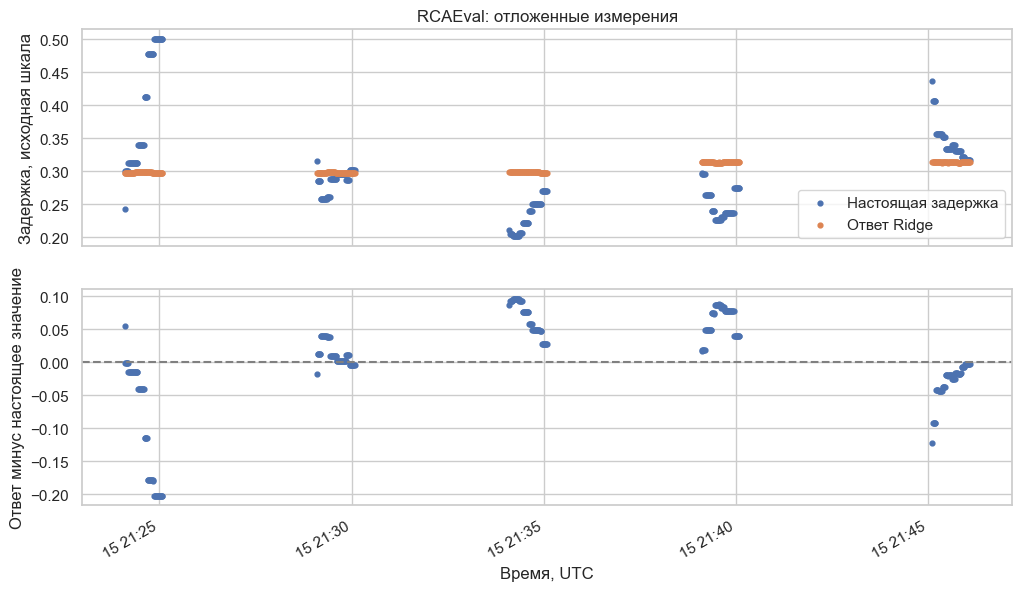

In [33]:
ordered = reg_answers.sort_values('time')
when = pd.to_datetime(ordered.time, unit='s', utc=True)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].scatter(when, ordered.actual, s=12, label='Настоящая задержка')
axes[0].scatter(when, ordered.prediction, s=12, label='Ответ Ridge')
axes[0].set(title='RCAEval: отложенные измерения', ylabel='Задержка, исходная шкала')
axes[0].legend()
axes[1].scatter(when, ordered.error, s=12)
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set(xlabel='Время, UTC', ylabel='Ответ минус настоящее значение')
fig.autofmt_xdate()
save_show(fig, '07_rca_time_errors.png')

Сверху сравниваются два значения в каждый проверочный момент. Снизу положительная ошибка означает завышение, отрицательная — занижение. Показаны только отложенные минуты, поэтому между группами точек есть промежутки. Модель не обучалась на этих строках.

### 3.5. Веса признаков и сохранение результатов

Показываем веса модели после масштабирования.

In [34]:
weights = pd.Series(ridge_model.named_steps['ridge'].coef_, index=regression_features, name='Вес')
display(weights)
print('Свободный член:', ridge_model.named_steps['ridge'].intercept_)

checkoutservice_cpu       0.003099
checkoutservice_mem       0.001837
checkoutservice_socket    0.002979
Name: Вес, dtype: float64

Свободный член: 0.30627410357253904


Вес относится к изменению подготовленного признака на одно стандартное отклонение обучения при фиксированных остальных признаках. Положительный знак повышает ответ, отрицательный понижает. Связанные признаки могут делить влияние между собой; веса сами по себе не доказывают причину изменения задержки.

Сохраняем таблицы регрессии и её ответы.

In [35]:
regression_metrics.to_csv(REPORT / 'regression_metrics.csv', index=False)
alpha_table.to_csv(REPORT / 'regression_alpha_cv.csv', index=False)
reg_answers.to_csv(REPORT / 'regression_predictions.csv', index=False)
weights.to_csv(REPORT / 'regression_coefficients.csv')
howpop_comparison.to_csv(REPORT / 'howpop_alpha.csv', index=False)

### 3.6. Формируем простой текст результата регрессии

Описываем качество модели относительно среднего ответа.

In [36]:
ridge_metrics = regression_metrics.loc[regression_metrics['Модель'] == 'Ridge'].iloc[0]
mean_metrics = regression_metrics.loc[regression_metrics['Модель'] == 'Среднее обучения'].iloc[0]
comparison_word = 'ниже' if ridge_metrics.MSE < mean_metrics.MSE else 'не ниже'
regression_analysis = (
    f'Оценивал текущую задержку checkoutservice по CPU, памяти и socket. Выбрано alpha = {best_alpha:.4g}. '
    f'На {len(yr_test)} отложенных строках средняя ошибка по модулю составила {ridge_metrics.MAE:.4f} в исходной шкале задержки. '
    f'MSE Ridge = {ridge_metrics.MSE:.5f}, baseline = {mean_metrics.MSE:.5f}: ошибка модели {comparison_word} ошибки среднего ответа. '
    'Модель использует три текущие метрики и не предсказывает будущее. Для переноса на другие сбои нужна отдельная проверка.')
display(Markdown(regression_analysis))

Оценивал текущую задержку checkoutservice по CPU, памяти и socket. Выбрано alpha = 1000. На 300 отложенных строках средняя ошибка по модулю составила 0.0543 в исходной шкале задержки. MSE Ridge = 0.00556, baseline = 0.00547: ошибка модели не ниже ошибки среднего ответа. Модель использует три текущие метрики и не предсказывает будущее. Для переноса на другие сбои нужна отдельная проверка.

### 3.7. Индивидуальные пункты про дерево, опубликованные на с. 82
Следующие шаги выполняют буквальный список из методички: параметры пользователя и PNG, два графика CV, совместный подбор, демонстрация, итоговый PNG и решающие границы. Это **дополнительная классификация периодов**, которая не заменяет выполненную выше регрессию задержки.

Дерево состоит из проверок вида «признак ≤ порог». `max_depth` ограничивает число уровней проверок. `max_features` — число признаков, рассматриваемых при поиске **одного разделения**, а не число столбцов входной таблицы.

В методичке график `1 − accuracy` назван MSE. Здесь сохраняем смысл её примера и подписываем его как **долю ошибок классификации**. Для бинарных меток 0/1 это также численно равно MSE меток. Для строковых видов Iris настоящая MSE не определена.

`gini` показывает смешанность классов в узле, `samples` — число обучающих строк, `value` — их распределение по классам. В используемой версии scikit-learn на рисунке с `proportion=False` показываются количества. Ответ листа — класс с наибольшим количеством строк.

Определяем функцию показа дерева в PNG.

In [37]:
def show_tree(model, features, names, filename):
    labels = {'checkoutservice_cpu': 'CPU', 'checkoutservice_mem': 'Память',
              'checkoutservice_latency-50': 'Медианная задержка', 'checkoutservice_socket': 'Socket'}
    short_features = [labels.get(name, name) for name in features]
    fig, ax = plt.subplots(figsize=(max(12, model.get_n_leaves() * 2.5),
                                    max(5, model.get_depth() * 1.8)))
    plot_tree(model, feature_names=short_features, class_names=names,
              filled=True, rounded=True, precision=3, fontsize=10, ax=ax)
    ax.set_title('Проверки и ответы дерева решений')
    save_show(fig, filename)

Определяем функцию построения двумерного среза выбранной модели.

In [38]:
def boundary_slice(model, training, features, names, ax):
    a, b = features
    gx = np.linspace(training[a].min(), training[a].max(), 150)
    gy = np.linspace(training[b].min(), training[b].max(), 150)
    xx, yy = np.meshgrid(gx, gy)
    grid = pd.DataFrame(np.tile(training.median().to_numpy(), (xx.size, 1)), columns=training.columns)
    grid[a], grid[b] = xx.ravel(), yy.ravel()
    regions = pd.Series(model.predict(grid)).map(dict(zip(model.classes_, range(len(names)))))
    ax.contourf(xx, yy, regions.to_numpy().reshape(xx.shape),
                levels=np.arange(len(names) + 1) - 0.5,
                cmap=ListedColormap(sns.color_palette('pastel', len(names))), alpha=0.8)
    ax.set(xlabel=a, ylabel=b)

На рисунках границ меняются два признака, а остальные фиксируются на медианах **обучающей** части. Цвет фона показывает ответы именно выбранной модели с полным набором признаков. Это срез её правила; он не показывает все возможные сочетания остальных признаков. На таких срезах не оцениваем accuracy.

Формируем задачу классификации для дополнительных пунктов.

In [39]:
rca_features = regression_features + [target_column]
X = df[rca_features].copy()
y = period
class_names = ['До внесения', 'После внесения']
X_dev, X_test = X.iloc[reg_dev_idx], X.iloc[reg_test_idx]
y_dev, y_test = y.iloc[reg_dev_idx], y.iloc[reg_test_idx]
groups_dev = reg_groups_dev
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

В классификации задержка снова является одним из четырёх входных признаков, а ответ — период. В регрессии выше задержка была ответом и не входила в признаки. Эти две задачи и их результаты разделены.

Задаём max_depth и max_features и обучаем дерево — пункт 2.1.

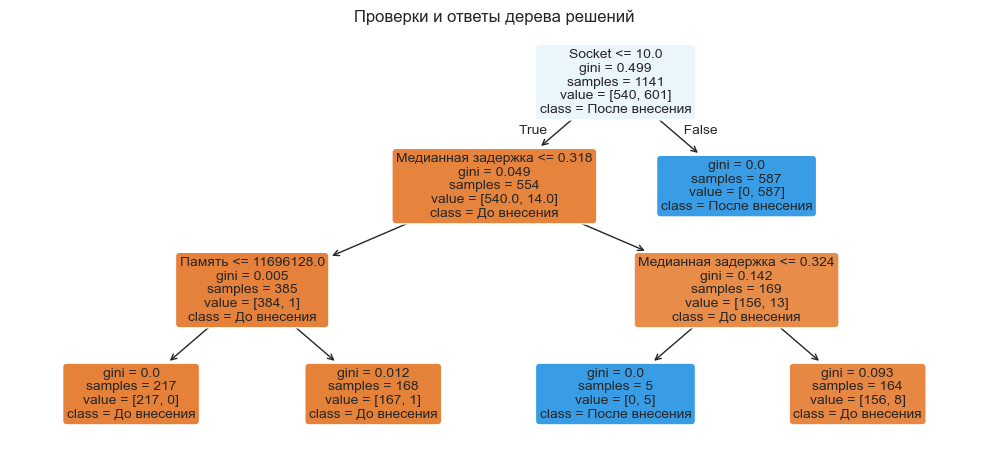

In [40]:
MAX_DEPTH_USER = 3
MAX_FEATURES_USER = 2
tree_user = DecisionTreeClassifier(max_depth=MAX_DEPTH_USER, max_features=MAX_FEATURES_USER,
                                   random_state=SEED).fit(X_dev, y_dev)
show_tree(tree_user, rca_features, class_names, '08_extra_user_tree.png')

Считаем CV-ошибки отдельно для глубины и числа признаков — пункты 2.2 и 2.3.

In [41]:
tree_depth_rows = []
for depth in range(1, 20):
    model = DecisionTreeClassifier(max_depth=depth, max_features=MAX_FEATURES_USER, random_state=SEED)
    scores = cross_val_score(model, X_dev, y_dev, groups=groups_dev, cv=cv, scoring='accuracy')
    tree_depth_rows.append({'max_depth': depth, 'error': 1 - scores.mean()})
tree_feature_rows = []
for count in [1, 2, 3, 4]:
    model = DecisionTreeClassifier(max_depth=MAX_DEPTH_USER, max_features=count, random_state=SEED)
    scores = cross_val_score(model, X_dev, y_dev, groups=groups_dev, cv=cv, scoring='accuracy')
    tree_feature_rows.append({'max_features': count, 'error': 1 - scores.mean()})
tree_depth_table = pd.DataFrame(tree_depth_rows)
tree_feature_table = pd.DataFrame(tree_feature_rows)

Строим два требуемых графика зависимости ошибки.

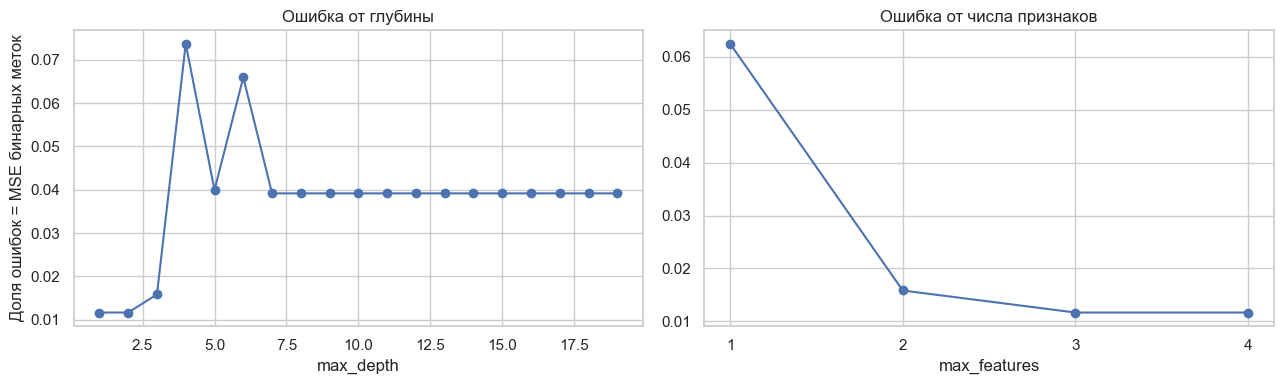

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(tree_depth_table.max_depth, tree_depth_table.error, marker='o')
axes[0].set(title='Ошибка от глубины', xlabel='max_depth', ylabel='Доля ошибок = MSE бинарных меток')
axes[1].plot(tree_feature_table.max_features, tree_feature_table.error, marker='o')
axes[1].set(title='Ошибка от числа признаков', xlabel='max_features', xticks=[1, 2, 3, 4])
fig.tight_layout()
save_show(fig, '09_extra_tree_cv.png')

Левый график меняет глубину при фиксированном max_features = 2; правый меняет max_features при глубине 3. Более низкие точки означают меньше ошибок. Для меток 0/1 доля неверных ответов равна MSE, поэтому здесь допустимы обе подписи.

Подбираем сочетание параметров дерева — пункт 2.4.

In [43]:
tree_grid = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
    {'max_depth': list(range(1, 20)), 'max_features': [1, 2, 3, 4]}, scoring='accuracy', cv=cv)
tree_grid.fit(X_dev, y_dev, groups=groups_dev)
extra_tree = tree_grid.best_estimator_
print('Выбрано:', tree_grid.best_params_, '| Средняя accuracy CV:', tree_grid.best_score_)

Выбрано: {'max_depth': 1, 'max_features': 1} | Средняя accuracy CV: 0.9883333333333333


Выбираем наибольшую среднюю accuracy на пяти частях. При равенстве используется первое сочетание сетки: меньшая глубина и затем меньшее max_features. Это выбор по обучающей части, а не по итоговым ответам.

Демонстрируем выбранное дерево на отложенных строках.

In [44]:
extra_prediction = extra_tree.predict(X_test)
extra_accuracy = accuracy_score(y_test, extra_prediction)
display(pd.DataFrame({'Настоящий период': y_test.iloc[:5].map(dict(enumerate(class_names))),
                      'Ответ модели': pd.Series(extra_prediction[:5], index=y_test.index[:5]).map(dict(enumerate(class_names)))}))
print('Итоговая accuracy дерева:', extra_accuracy)

,Настоящий период,Ответ модели
0,До внесения,До внесения
1,До внесения,До внесения
2,До внесения,До внесения
3,До внесения,До внесения
4,До внесения,До внесения


Итоговая accuracy дерева: 1.0


Сохраняем итоговое дерево в PNG — пункт 2.5.

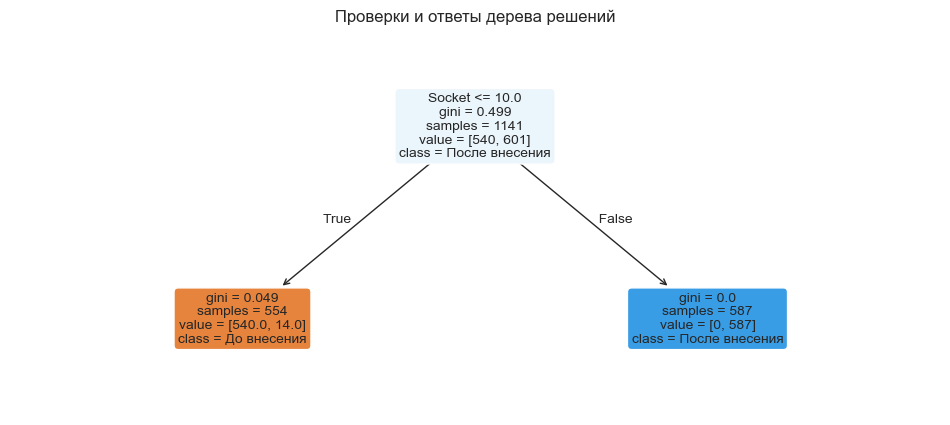

|--- checkoutservice_socket <= 10.00
|   |--- class: 0
|--- checkoutservice_socket >  10.00
|   |--- class: 1



In [45]:
show_tree(extra_tree, rca_features, class_names, '10_extra_best_tree.png')
print(export_text(extra_tree, feature_names=rca_features))

По условиям на рисунке и в тексте можно повторить путь от метрик новой строки до ответа «до» или «после». Эти ответы являются категориями, а не оценкой числовой задержки.

Выводим срезы решающих границ выбранного дерева — пункт 2.6.

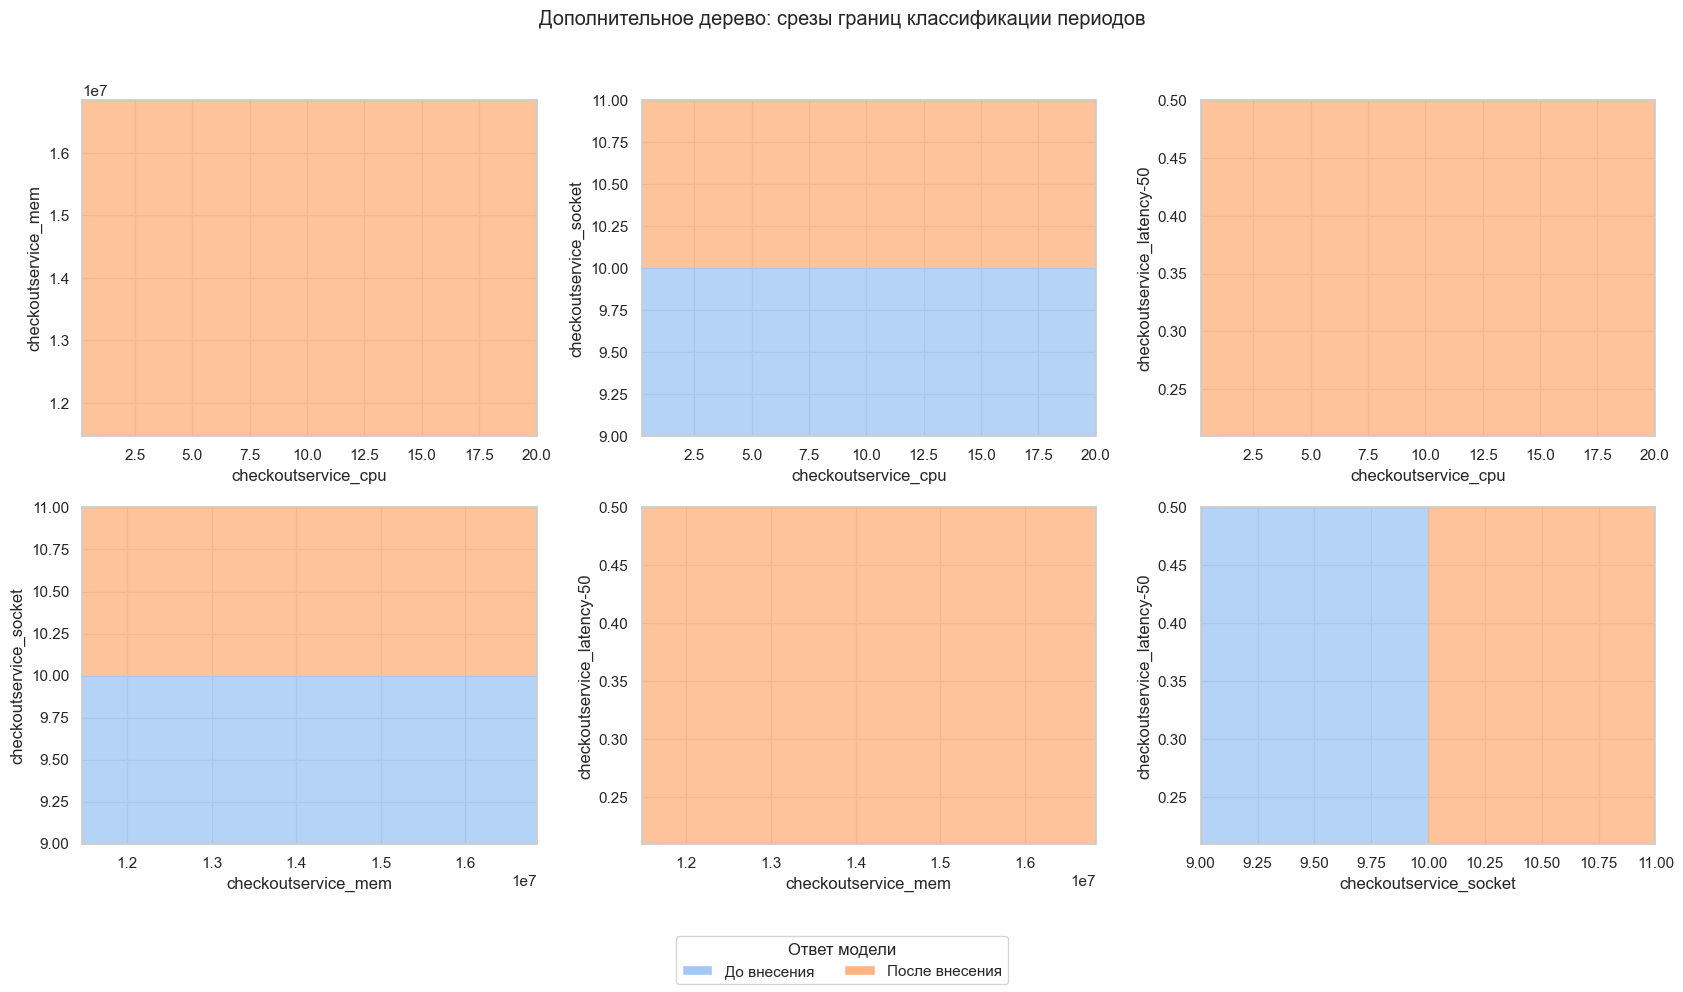

In [46]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, pair in zip(axes.flat, combinations(rca_features, 2)):
    boundary_slice(extra_tree, X_dev, pair, class_names, ax)
fig.suptitle('Дополнительное дерево: срезы границ классификации периодов')
fig.legend(handles=[Patch(facecolor=color, label=name) for color, name in
                    zip(sns.color_palette('pastel', len(class_names)), class_names)],
           loc='lower center', ncol=len(class_names), title='Ответ модели')
fig.tight_layout(rect=(0, 0.08, 1, 0.96))
save_show(fig, '11_extra_boundaries.png')

Фон показывает ответы выбранного дерева по двум меняющимся признакам при фиксированных медианах остальных. Если цвет не меняется, эта пара в таком срезе не меняет ответ. Рисунок помогает понять правило; итоговая accuracy рассчитана на полных строках с четырьмя признаками.

Сохраняем результаты дополнительных пунктов и общий итог.

In [47]:
tree_depth_table.to_csv(REPORT / 'extra_tree_depth.csv', index=False)
tree_feature_table.to_csv(REPORT / 'extra_tree_features.csv', index=False)
analysis = regression_analysis + '\n\n' + (
    f'Также выполнены опубликованные пункты про дерево: параметры {tree_grid.best_params_}, '
    f'accuracy на отложенных строках {extra_accuracy:.1%}. Сохранены PNG и графики CV и границ.')
(REPORT / 'analysis.md').write_text(analysis, encoding='utf-8')
summary = {'case': case, 'regression_target': target_column, 'regression_features': regression_features,
           'alpha': best_alpha, 'test_rows': len(yr_test), 'Ridge_MSE': float(ridge_metrics.MSE),
           'Ridge_MAE': float(ridge_metrics.MAE), 'Ridge_R2': float(ridge_metrics.R2),
           'baseline_MSE': float(mean_metrics.MSE), 'howpop_alpha': howpop_best_alpha,
           'howpop_validation_MSE': mean_squared_error(yh_valid, howpop_prediction),
           'howpop_train_rows': len(articles), 'howpop_test_rows': len(articles_test),
           'extra_tree_params': tree_grid.best_params_, 'extra_tree_accuracy': extra_accuracy,
           'course_revision': course_revision, 'figures': sorted(p.name for p in FIGURES.glob('*.png'))}
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
display(Markdown(analysis))

Оценивал текущую задержку checkoutservice по CPU, памяти и socket. Выбрано alpha = 1000. На 300 отложенных строках средняя ошибка по модулю составила 0.0543 в исходной шкале задержки. MSE Ridge = 0.00556, baseline = 0.00547: ошибка модели не ниже ошибки среднего ответа. Модель использует три текущие метрики и не предсказывает будущее. Для переноса на другие сбои нужна отдельная проверка.

Также выполнены опубликованные пункты про дерево: параметры {'max_depth': 1, 'max_features': 1}, accuracy на отложенных строках 100.0%. Сохранены PNG и графики CV и границ.

Сохраняем сведения об исходных файлах.

In [48]:
source_files = [HOWPOP / 'howpop_train.csv', HOWPOP / 'howpop_test.csv', metrics_path, inject_path]
sources = {'rcaeval': selection, 'sha256': {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in source_files}}
(REPORT / 'sources.json').write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding='utf-8')

1087